# Zero-Shot Topic Classification of AI-Related Discourse (Sector-Year Evolution)

This notebook classifies AI-related textual occurrences into strategic topics using a zero-shot transformer model and analyzes how topic composition evolves across sectors and years.

## Methodology 

1. Use metadata and document-level outputs from the first notebook to focus on AI-relevant documents.
2. Re-extract text from PDFs
3. Apply a zero-shot NLI model to assign one topic label per snippet from:
   - Cost Reduction & Operational Efficiency
   - Revenue Generation & Product Innovation
   - Supply Chain & Inventory Logistics
   - Governance, Risk & Ethics
4. Aggregate predictions by sector and year; visualize counts and shares with line/area charts and heatmaps.

This design emphasizes temporal and sectoral dynamics rather than single-enterprise case profiles.

In [22]:
from pathlib import Path
import json
import re
from collections import Counter
from time import perf_counter
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import fitz
from pypdf import PdfReader
import pdfplumber

from transformers import pipeline

In [11]:
ROOT = Path.cwd()
META_PATH = ROOT / 'data' / 'metadata.json'
DOC_LEVEL_PATH = ROOT / 'data' / 'ai_eligibility_doc_level.csv'

with META_PATH.open('r', encoding='utf-8') as f:
    meta = json.load(f)

df_meta = pd.DataFrame(meta)
df_doc = pd.read_csv(DOC_LEVEL_PATH)

SECTOR_MAP = {
    'Nestlé S.A.': 'FMCG',
    'Unilever PLC': 'FMCG',
    'Procter & Gamble Co.': 'FMCG',
    'Colgate-Palmolive Co.': 'FMCG',
    'PepsiCo, Inc.': 'FMCG',
    'Ceconomy AG': 'Hardlines',
    'Electrolux AB': 'Hardlines',
    'The Home Depot, Inc.': 'Hardlines',
    'Kingfisher plc': 'Hardlines',
    'Whirlpool Corporation': 'Hardlines',
}

df = df_meta.merge(df_doc[['path', 'eligible']], on='path', how='left')
df['eligible'] = df['eligible'].fillna(False).astype(bool)
df['sector'] = df['company'].map(SECTOR_MAP).fillna('Unknown')
df['abs_path'] = df['path'].map(lambda p: ROOT / p)

df = df[df['eligible']].copy()
df.shape

(89, 7)

In [13]:
TOPIC_LABELS = [
    'Cost Reduction & Operational Efficiency',
    'Revenue Generation & Product Innovation',
    'Supply Chain & Inventory Logistics',
    'Governance, Risk & Ethics'
]

TERM_PATTERNS = {
    'ai': r'\bartificial intelligence\b|\bai\b|\bai[- ]?(enabled|driven|powered|based|assisted|augmented)\b',
    'genai': r'\bgenerative ai\b|\bgen\s*ai\b|\bgenai\b|\bai[- ]generated\b',
    'machine_learning': r'\bmachine learning\b|\bml\b|\bmachine[- ]learn(ing|ed)\b|\bml[- ]?(enabled|driven|based)\b',
    'deep_learning': r'\bdeep learning\b|\bdeep[- ]learn(ing|ed)\b',
    'llm': r'\blarge language model(s)?\b|\bllm(s)?\b|\bfoundation model(s)?\b|\bgpt[- ]?[2345]\b|\btransformer model(s)?\b',
    'nlp': r'\bnatural language processing\b|\bnlp\b|\blanguage model(s)?\b',
    'computer_vision': r'\bcomputer vision\b|\bvision model(s)?\b|\bimage recognition\b',
    'neural_networks': r'\bneural network(s)?\b|\bneural net(s)?\b|\bcnn(s)?\b|\brnn(s)?\b',
    'data_engineering': r'\bdata engineering\b|\bdata pipeline(s)?\b|\betl\b|\belt\b|\bdata platform(s)?\b|\bdata architecture\b|\bdata lake(s)?\b|\bdata warehouse(s)?\b',
    'mlops': r'\bmlops\b|\bmodel ops\b|\bmodel operations\b|\bmodel deployment\b|\bmodel monitoring\b',
    'training_inference': r'\bmodel training\b|\binference\b|\bfine[- ]?tuning\b|\bprompt engineering\b',
    'adjacent_analytics': r'\bpredictive analytics\b|\bpredictive model(s|ling)?\b|\badvanced analytics\b|\balgorithmic\b'
}

COMPILED_PATTERNS = {k: re.compile(v, flags=re.IGNORECASE) for k, v in TERM_PATTERNS.items()}


In [15]:
def clean_text(text: str) -> str:
    if not text:
        return ''
    text = re.sub(r'-\n', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

def extract_text_pymupdf(pdf_path: Path) -> str:
    chunks = []
    with fitz.open(pdf_path) as doc:
        for page in doc:
            chunks.append(page.get_text('text') or '')
    return '\n'.join(chunks)

def extract_text_pypdf(pdf_path: Path) -> str:
    reader = PdfReader(str(pdf_path))
    return '\n'.join((page.extract_text() or '') for page in reader.pages)

def extract_text_pdfplumber(pdf_path: Path) -> str:
    chunks = []
    with pdfplumber.open(str(pdf_path)) as pdf:
        for page in pdf.pages:
            chunks.append(page.extract_text() or '')
    return '\n'.join(chunks)

def robust_extract_text(pdf_path: Path):
    engines = [
        ('pymupdf', extract_text_pymupdf),
        ('pypdf', extract_text_pypdf),
        ('pdfplumber', extract_text_pdfplumber),
    ]
    for name, fn in engines:
        try:
            txt = clean_text(fn(pdf_path))
            if txt and len(txt) > 50:
                return txt, name
        except Exception:
            pass
    return '', 'failed'

def sentence_split(text: str):
    return re.split(r'(?<=[\.!?])\s+', text)

def contains_any_term(sentence: str, compiled_patterns: dict) -> bool:
    return any(pattern.search(sentence) for pattern in compiled_patterns.values())

def build_ai_snippets(text: str, window: int = 1):
    sents = sentence_split(text)
    snippets = []
    for i, s in enumerate(sents):
        if contains_any_term(s, COMPILED_PATTERNS):
            lo = max(0, i - window)
            hi = min(len(sents), i + window + 1)
            snippet = ' '.join(sents[lo:hi]).strip()
            if len(snippet) >= 30:
                snippets.append(snippet)
    return snippets

In [16]:
snippet_rows = []
for row in df.itertuples(index=False):
    p = Path(row.abs_path)
    if not p.exists():
        continue

    text, engine = robust_extract_text(p)
    if not text:
        continue

    snippets = build_ai_snippets(text, window=1)
    for j, sn in enumerate(snippets):
        snippet_rows.append({
            'path': row.path,
            'company': row.company,
            'sector': row.sector,
            'year': int(row.year),
            'category': row.category,
            'extractor': engine,
            'snippet_id': j,
            'snippet': sn
        })

df_snippets = pd.DataFrame(snippet_rows)
print('AI-related snippets:', len(df_snippets))
df_snippets.head()

AI-related snippets: 553


,path,company,sector,year,category,extractor,snippet_id,snippet
0,data/Ceconomy/CECONOMY Annual Report 2024-25.pdf,Ceconomy AG,Hardlines,2024,annual reports,pymupdf,0,Our employee experience empowers our teams to ...
1,data/Ceconomy/CECONOMY Annual Report 2024-25.pdf,Ceconomy AG,Hardlines,2024,annual reports,pymupdf,1,And they develop effective solutions. While AI...
2,data/Ceconomy/CECONOMY Annual Report 2024-25.pdf,Ceconomy AG,Hardlines,2024,annual reports,pymupdf,2,The market volume across our eleven countries ...
3,data/Ceconomy/CECONOMY Annual Report 2024-25.pdf,Ceconomy AG,Hardlines,2024,annual reports,pymupdf,3,Durch den konsequenten Einsatz von Daten und K...
4,data/Ceconomy/CECONOMY Annual Report 2024-25.pdf,Ceconomy AG,Hardlines,2024,annual reports,pymupdf,4,Platform 53 m Loyalty members + 10 m vs. PY 61...


In [ ]:
try:
    import torch
    if torch.backends.mps.is_available():
        device = 0
    elif torch.cuda.is_available():
        device = 0
    else:
        device = -1
except Exception:
    device = -1

MODEL_NAME = 'facebook/bart-large-mnli'

clf = pipeline(
    'zero-shot-classification',
    model=MODEL_NAME,
    device=device
 )

def _clean_for_inference(x: str) -> str:
    return str(x).strip()[:1200]

start = perf_counter()

unique_snippets = (
    df_snippets['snippet']
    .dropna()
    .map(_clean_for_inference)
    .loc[lambda s: s.str.len() > 0]
    .drop_duplicates()
    .tolist()
 )

BATCH_SIZE = 16 if device != -1 else 8
pred_map = {}

for i in range(0, len(unique_snippets), BATCH_SIZE):
    batch = unique_snippets[i:i + BATCH_SIZE]
    print(i/len(unique_snippets))
    out = clf(
        batch,
        TOPIC_LABELS,
        multi_label=False,
        truncation=True
    )
    if isinstance(out, dict):
        out = [out]
    for text, pred in zip(batch, out):
        pred_map[text] = (pred['labels'][0], float(pred['scores'][0]))

cleaned_all = df_snippets['snippet'].map(_clean_for_inference)
df_snippets['topic'] = cleaned_all.map(lambda t: pred_map.get(t, (None, np.nan))[0])
df_snippets['topic_score'] = cleaned_all.map(lambda t: pred_map.get(t, (None, np.nan))[1])

elapsed = perf_counter() - start
n_unique = len(unique_snippets)
n_total = len(df_snippets)
print(f'Classified {n_total} snippets ({n_unique} unique) in {elapsed:.1f}s; batch_size={BATCH_SIZE}, device={device}')
df_snippets[['topic', 'topic_score']].head()
df_snippets.to_csv("data/snippets.csv", index=False)

In [34]:
topic_sector_year = (
    df_snippets.groupby(['sector', 'year', 'topic'], as_index=False)
    .size()
    .rename(columns={'size': 'snippet_count'})
)

topic_sector_year['topic_share_pct'] = (
    100 * topic_sector_year['snippet_count'] / topic_sector_year.groupby(['sector', 'year'])['snippet_count'].transform('sum')
)

topic_overall_year = (
    df_snippets.groupby(['year', 'topic'], as_index=False)
    .size()
    .rename(columns={'size': 'snippet_count'})
)

topic_overall_year['topic_share_pct'] = (
    100 * topic_overall_year['snippet_count'] / topic_overall_year.groupby('year')['snippet_count'].transform('sum')
)

topic_sector_year.head()

,sector,year,topic,snippet_count,topic_share_pct
0,FMCG,2021,Cost Reduction & Operational Efficiency,3,12.500000
1,FMCG,2021,"Governance, Risk & Ethics",6,25.000000
2,FMCG,2021,Revenue Generation & Product Innovation,10,41.666667
3,FMCG,2021,Supply Chain & Inventory Logistics,5,20.833333
4,FMCG,2022,Cost Reduction & Operational Efficiency,13,43.333333


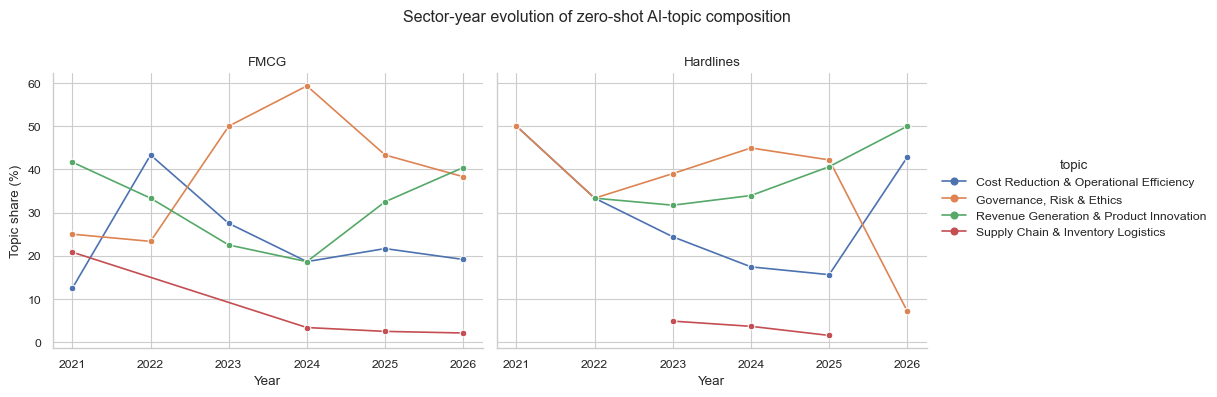

In [35]:
sns.set_theme(style='whitegrid', context='paper')

g = sns.relplot(
    data=topic_sector_year,
    x='year', y='topic_share_pct',
    hue='topic', col='sector',
    kind='line', marker='o',
    height=4, aspect=1.2
)
g.set_axis_labels('Year', 'Topic share (%)')
g.set_titles('{col_name}')
g.figure.subplots_adjust(top=0.82)
g.figure.suptitle('Sector-year evolution of zero-shot AI-topic composition')
plt.show()

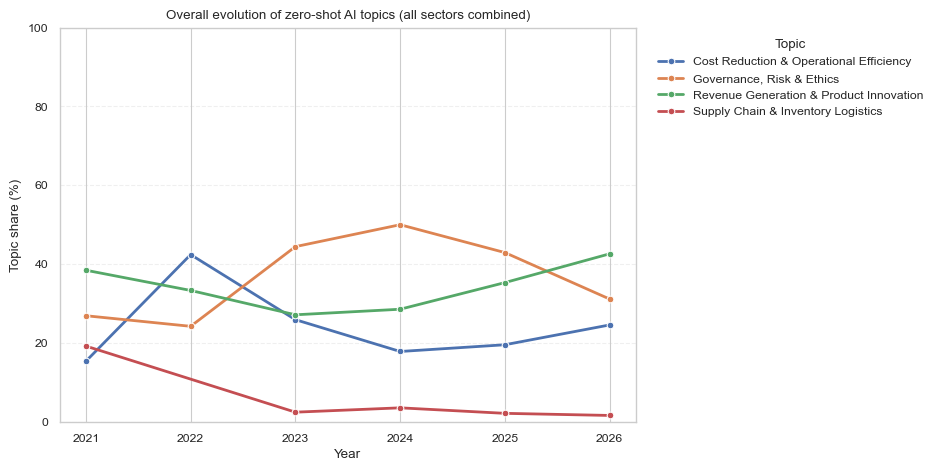

In [37]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.lineplot(
    data=topic_overall_year,
    x='year', y='topic_share_pct',
    hue='topic',
    marker='o', linewidth=2,
    ax=ax
)
ax.set_title('Overall evolution of zero-shot AI topics (all sectors combined)')
ax.set_xlabel('Year')
ax.set_ylabel('Topic share (%)')
ax.set_ylim(0, 100)
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(title='Topic', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
plt.tight_layout()
plt.show()

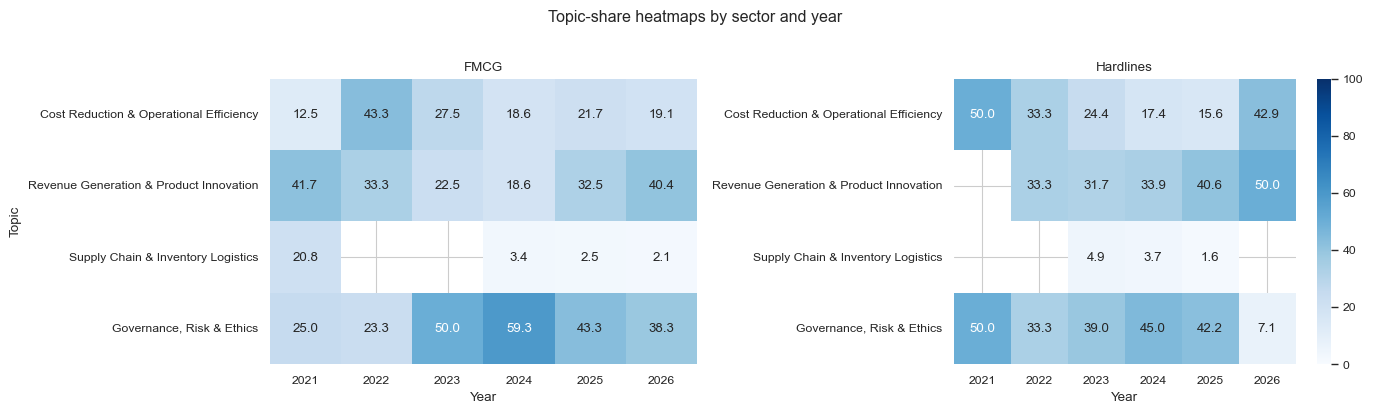

In [36]:
sectors = sorted(topic_sector_year['sector'].unique())
fig, axes = plt.subplots(1, len(sectors), figsize=(7 * len(sectors), 4), squeeze=False)

for i, sec in enumerate(sectors):
    tmp = topic_sector_year[topic_sector_year['sector'] == sec]
    heat = tmp.pivot(index='topic', columns='year', values='topic_share_pct').reindex(TOPIC_LABELS)
    sns.heatmap(
        heat, annot=True, fmt='.1f', cmap='Blues',
        vmin=0, vmax=100, cbar=(i == len(sectors) - 1),
        ax=axes[0, i]
    )
    axes[0, i].set_title(sec)
    axes[0, i].set_xlabel('Year')
    axes[0, i].set_ylabel('Topic' if i == 0 else '')

fig.suptitle('Topic-share heatmaps by sector and year', y=1.02)
plt.tight_layout()
plt.show()